In [1]:
!pip -q install interpret

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import os, json, shutil, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import joblib
warnings.filterwarnings('ignore')
from google.colab import files
os.makedirs('out', exist_ok=True)
SEED = 42

up = files.upload()
FILE = list(up.keys())[0]

Saving Raw_Data_on_Challenges_and_Resilience_Capacities_of_Smallholder_Farmers_in_Sri_Lanka.xlsx to Raw_Data_on_Challenges_and_Resilience_Capacities_of_Smallholder_Farmers_in_Sri_Lanka.xlsx


In [3]:

def sheet(n):
    d = pd.read_excel(FILE, sheet_name=n)
    d.columns = [str(c).strip() for c in d.columns]
    return d

soc, ch, rc, rs = (sheet(n) for n in ['Socio-economic and farm mgt', 'Agricultural Challenges',
                                       'Resilience Capacities', 'Risk Management Strategies'])

soc = soc.replace({
    'Ownership of the land': {1: 'Own', 2: 'Leasehold', 3: 'Common'},
    'Animal rearing system': {0: 'None', 1: 'Intensive', 2: 'Semi-intensive', 3: 'Extensive'},
    'Marital status': {1: 'Married', 2: 'Single', 3: 'Widow'},
    'Gender of farmer': {1: 'Female', 2: 'Male'},
    'Gender of household head': {1: 'Female', 2: 'Male'},
    'Type of farming': {1: 'Conventional', 2: 'Organic (not certified)', 3: 'Organic (certified)'}})

ch = ch.rename(columns=lambda c: c if c == 'No' else 'CH: ' + c)
rs = rs.loc[:, (rs.nunique() > 1) | (rs.columns == 'No')]
rs = rs.rename(columns=lambda c: c if c == 'No' else 'RM: ' + c[:45])

# target: mean of the 6 resilience-capacity items (1-5), High = above median
items = rc.drop(columns='No')
score = items.mean(axis=1)
thr = score.median()
y = (score > thr).astype(int)
k = items.shape[1]
alpha = k / (k - 1) * (1 - items.var().sum() / items.sum(axis=1).var())

X = soc.merge(ch, on='No').merge(rs, on='No').drop(columns='No')
assert X.shape[0] == len(y) == 300 and X.columns.is_unique

summary = {'rows': int(len(X)), 'features': int(X.shape[1]),
           'socio_economic': int(soc.shape[1] - 1), 'challenges': int(ch.shape[1] - 1),
           'risk_strategies': int(rs.shape[1] - 1), 'missing_values': int(X.isna().sum().sum()),
           'target_median_threshold': float(thr), 'cronbach_alpha': round(float(alpha), 3),
           'high_share': round(float(y.mean()), 3)}
json.dump(summary, open('out/dataset_summary.json', 'w'), indent=1)
print(summary)
print(score.describe().round(2).to_dict())

{'rows': 300, 'features': 72, 'socio_economic': 31, 'challenges': 20, 'risk_strategies': 21, 'missing_values': 0, 'target_median_threshold': 2.3333333333333335, 'cronbach_alpha': 0.757, 'high_share': 0.497}
{'count': 300.0, 'mean': 2.5, 'std': 0.77, 'min': 1.0, '25%': 1.83, '50%': 2.33, '75%': 3.04, 'max': 4.5}


In [4]:
# split + preprocessing for baselines
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=SEED, stratify=y)
print('train/test:', X_tr.shape, X_te.shape, '| High share:', round(y_tr.mean(), 3), round(y_te.mean(), 3))

cat_cols = X.select_dtypes(exclude='number').columns.tolist()
num_cols = [c for c in X.columns if c not in cat_cols]
prep = lambda: ColumnTransformer([('n', StandardScaler(), num_cols),
                                  ('c', OneHotEncoder(handle_unknown='ignore'), cat_cols)])
print(len(num_cols), 'numeric/ordinal,', len(cat_cols), 'categorical')

train/test: (240, 72) (60, 72) | High share: 0.496 0.5
66 numeric/ordinal, 6 categorical


In [5]:
# models + EBM tuning (5-fold stratified CV on train)
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from interpret.glassbox import ExplainableBoostingClassifier

cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
grid = {'learning_rate': [0.01, 0.05], 'interactions': [0, 5]}
gs = GridSearchCV(ExplainableBoostingClassifier(random_state=SEED), grid, cv=cv,
                  scoring='roc_auc', n_jobs=1).fit(X_tr, y_tr)
ebm = gs.best_estimator_
print('best EBM params:', gs.best_params_, '| CV AUC', round(gs.best_score_, 4))
pd.DataFrame(gs.cv_results_)[['params', 'mean_test_score', 'std_test_score']].to_csv('out/ebm_grid.csv', index=False)

base = {'Logistic Regression': LogisticRegression(C=0.1, max_iter=2000),
        'Random Forest': RandomForestClassifier(300, random_state=SEED),
        'Gradient Boosting': GradientBoostingClassifier(random_state=SEED)}
models = {n: Pipeline([('p', prep()), ('m', m)]).fit(X_tr, y_tr) for n, m in base.items()}
models['EBM'] = ebm

best EBM params: {'interactions': 0, 'learning_rate': 0.01} | CV AUC 0.6238


In [6]:
# cross-validation + held-out test results
from sklearn.model_selection import cross_validate
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from sklearn.base import clone

scoring = {'Accuracy': 'accuracy', 'F1': 'f1_macro', 'AUC': 'roc_auc'}

def evaluate(m, Xs, ys):
    p = m.predict_proba(Xs)[:, 1]; yh = (p >= .5).astype(int)
    return {'Accuracy': accuracy_score(ys, yh), 'F1': f1_score(ys, yh, average='macro'), 'AUC': roc_auc_score(ys, p)}

cv_rows, te_rows = {}, {}
for n, m in models.items():
    r = cross_validate(clone(m), X_tr, y_tr, cv=cv, scoring=scoring)
    cv_rows[n] = {k: f"{r['test_'+k].mean():.3f} ± {r['test_'+k].std():.3f}" for k in scoring}
    te_rows[n] = {k: round(v, 3) for k, v in evaluate(m, X_te, y_te).items()}
cv_tbl, te_tbl = pd.DataFrame(cv_rows).T, pd.DataFrame(te_rows).T
cv_tbl.to_csv('out/cv_results.csv'); te_tbl.to_csv('out/test_results.csv')
print('5-fold CV (train):'); display(cv_tbl)
print('Held-out test:'); display(te_tbl)

5-fold CV (train):


,Accuracy,F1,AUC
Logistic Regression,0.537 ± 0.061,0.535 ± 0.060,0.548 ± 0.058
Random Forest,0.646 ± 0.068,0.642 ± 0.067,0.658 ± 0.068
Gradient Boosting,0.571 ± 0.068,0.566 ± 0.066,0.604 ± 0.068
EBM,0.592 ± 0.064,0.589 ± 0.065,0.624 ± 0.053


Held-out test:


,Accuracy,F1,AUC
Logistic Regression,0.600,0.598,0.592
Random Forest,0.667,0.666,0.742
Gradient Boosting,0.667,0.663,0.659
EBM,0.633,0.627,0.659


              precision    recall  f1-score   support

         Low       0.61      0.77      0.68        30
        High       0.68      0.50      0.58        30

    accuracy                           0.63        60
   macro avg       0.64      0.63      0.63        60
weighted avg       0.64      0.63      0.63        60



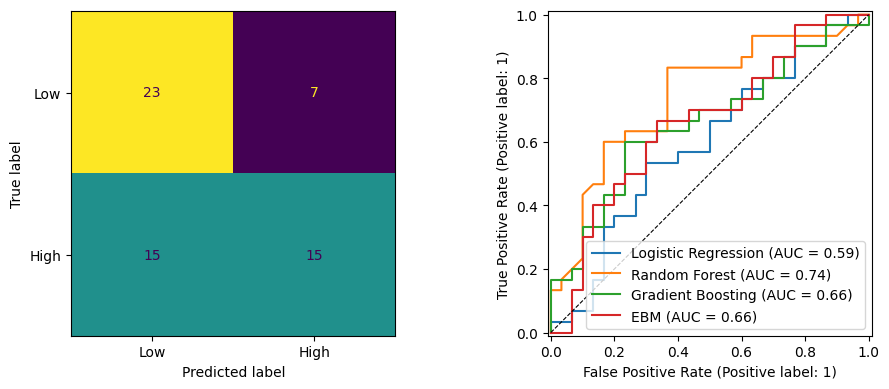

In [7]:
# EBM evaluation plots
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, classification_report

print(classification_report(y_te, ebm.predict(X_te), target_names=['Low', 'High']))
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay.from_estimator(ebm, X_te, y_te, display_labels=['Low', 'High'], ax=ax[0], colorbar=False)
for n, m in models.items():
    RocCurveDisplay.from_estimator(m, X_te, y_te, ax=ax[1], name=n)
ax[1].plot([0, 1], [0, 1], 'k--', lw=.8)
plt.tight_layout(); plt.savefig('out/fig_eval.png', dpi=200); plt.show()

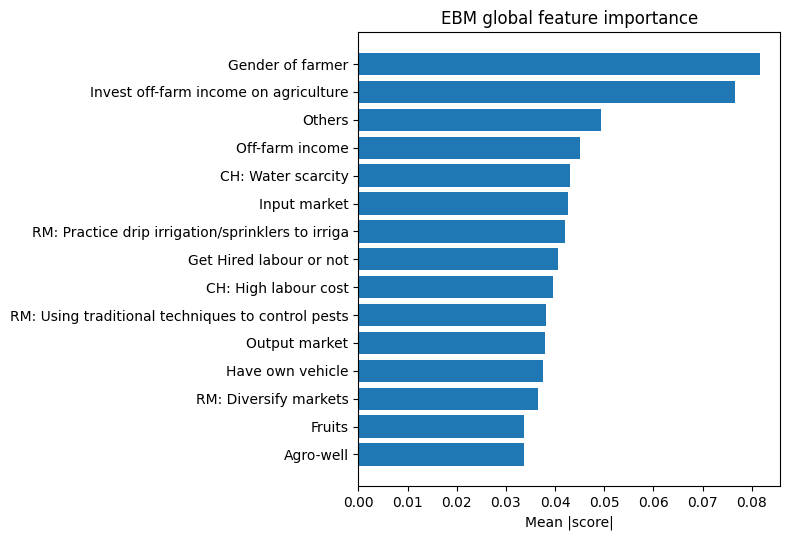

,0
Gender of farmer,0.0816
Invest off-farm income on agriculture,0.0766
Others,0.0493
Off-farm income,0.0450
CH: Water scarcity,0.0429
Input market,0.0426
RM: Practice drip irrigation/sprinklers to irriga,0.0419
Get Hired labour or not,0.0406
CH: High labour cost,0.0396
RM: Using traditional techniques to control pests,0.0382


Challenges         0.247
Risk strategies    0.280
Socio-economic     0.473
dtype: float64


In [8]:
# global explanation: EBM term importance
names = ebm.term_names_
imp = pd.Series(ebm.term_importances(), index=names).sort_values(ascending=False)
imp.to_csv('out/ebm_importance.csv')
top = imp.head(15)[::-1]
plt.figure(figsize=(8, 5.5)); plt.barh(top.index, top.values)
plt.xlabel('Mean |score|'); plt.title('EBM global feature importance')
plt.tight_layout(); plt.savefig('out/fig_ebm_importance.png', dpi=200); plt.show()
display(imp.head(10).round(4))

grp = lambda n: 'Challenges' if n.startswith('CH:') else 'Risk strategies' if n.startswith('RM:') else 'Socio-economic'
share = imp.groupby(imp.index.map(grp)).sum() / imp.sum()
share.round(3).to_csv('out/importance_by_group.csv'); print(share.round(3))

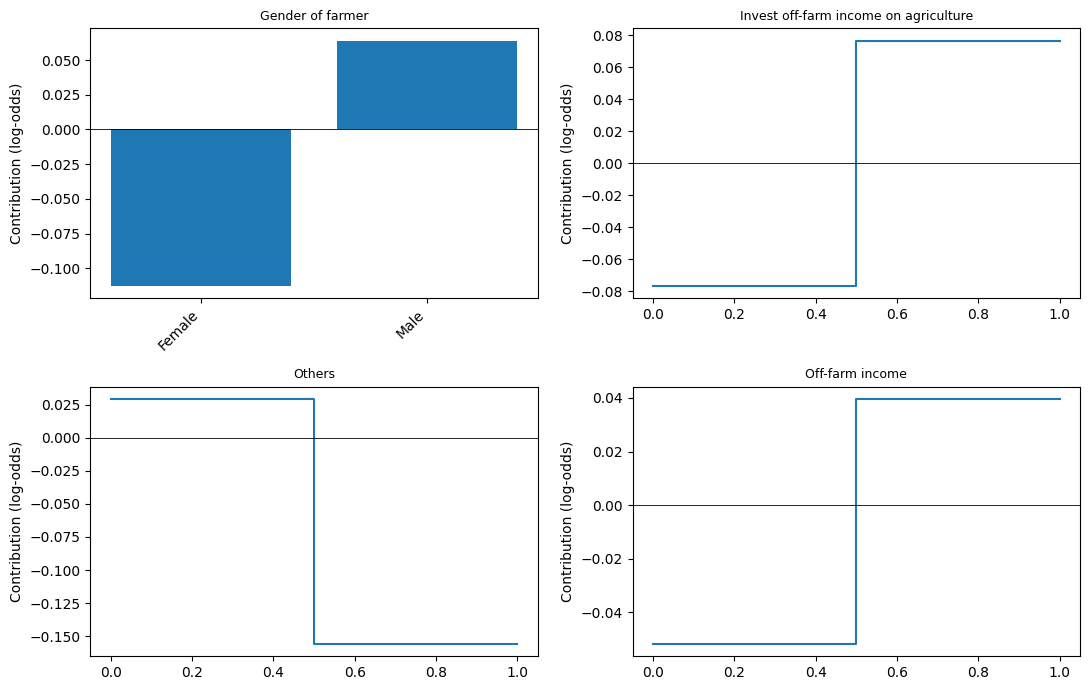

In [9]:
# shape functions of top single-feature terms
g = ebm.explain_global()
single = [n for n in imp.index if ' & ' not in n][:4]
fig, axs = plt.subplots(2, 2, figsize=(11, 7))
for a, n in zip(axs.ravel(), single):
    d = g.data(names.index(n)); x, s = d['names'], np.asarray(d['scores'])
    if len(x) == len(s) + 1:
        a.step(x, np.r_[s, s[-1]], where='post')
    else:
        a.bar(range(len(s)), s); a.set_xticks(range(len(s))); a.set_xticklabels(x, rotation=45, ha='right')
    a.axhline(0, color='k', lw=.6); a.set_title(n, fontsize=9); a.set_ylabel('Contribution (log-odds)')
plt.tight_layout(); plt.savefig('out/fig_shape_functions.png', dpi=200); plt.show()

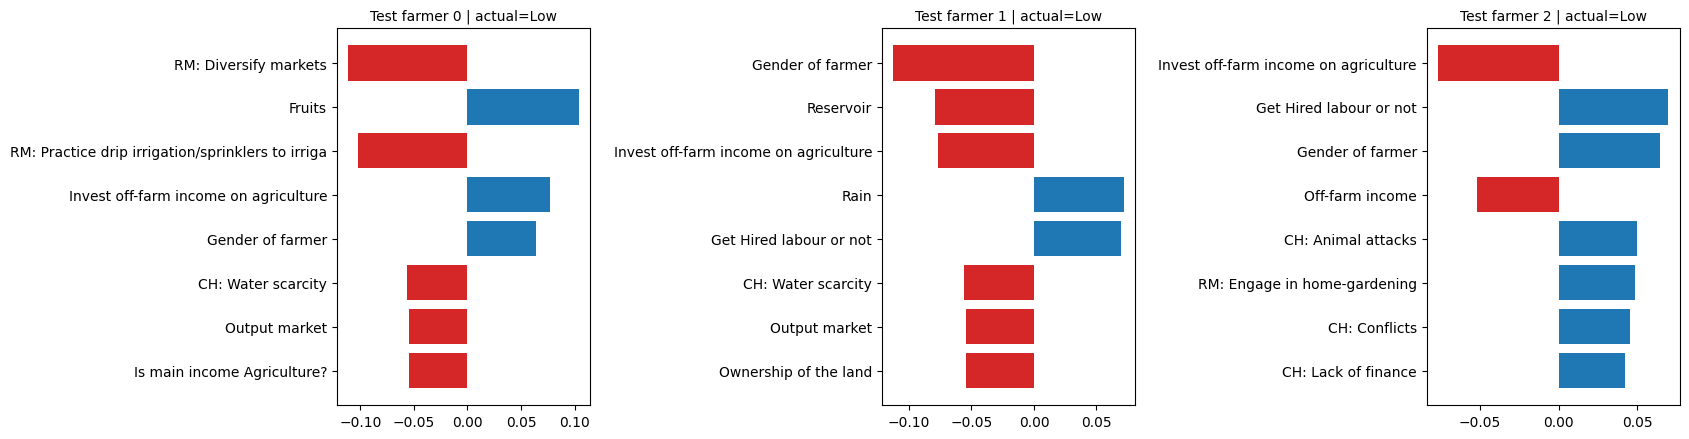

In [10]:
# local explanations (3 test farmers)
loc = ebm.explain_local(X_te.iloc[:3], y_te.iloc[:3])
fig, axs = plt.subplots(1, 3, figsize=(17, 4.5))
for i, a in enumerate(axs):
    d = loc.data(i)
    s = pd.Series(d['scores'], index=d['names']).sort_values(key=abs).tail(8)
    a.barh(s.index, s.values, color=['tab:red' if v < 0 else 'tab:blue' for v in s.values])
    a.set_title(f"Test farmer {i} | actual={'High' if y_te.iloc[i] else 'Low'}", fontsize=10)
plt.tight_layout(); plt.savefig('out/fig_local.png', dpi=200); plt.show()

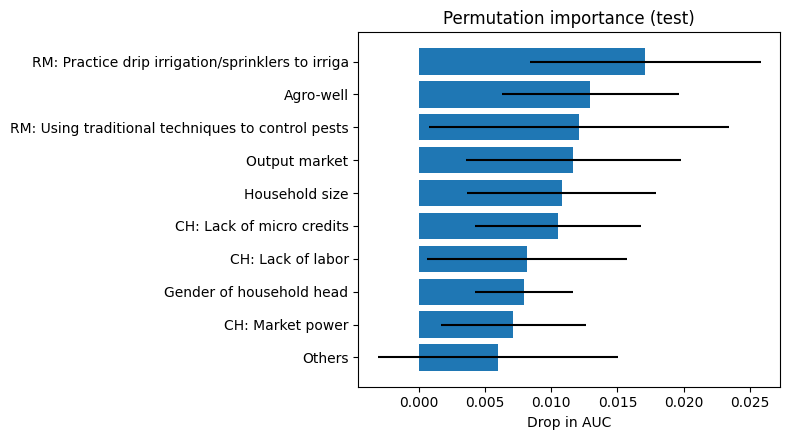

In [11]:
# permutation importance (second method, test set)
from sklearn.inspection import permutation_importance
pi = permutation_importance(ebm, X_te, y_te, scoring='roc_auc', n_repeats=30, random_state=SEED)
pi_s = pd.Series(pi.importances_mean, index=X.columns).sort_values(ascending=False)
pi_s.to_csv('out/permutation_importance.csv')
t = pi_s.head(10)[::-1]; e = pd.Series(pi.importances_std, index=X.columns)[t.index]
plt.figure(figsize=(8, 4.5)); plt.barh(t.index, t.values, xerr=e.values)
plt.xlabel('Drop in AUC'); plt.title('Permutation importance (test)')
plt.tight_layout(); plt.savefig('out/fig_permutation.png', dpi=200); plt.show()

In [12]:
# stability of EBM across CV folds
ranks = []
for tr, _ in cv.split(X_tr, y_tr):
    m = clone(ebm).fit(X_tr.iloc[tr], y_tr.iloc[tr])
    ranks.append(pd.Series(m.term_importances(), index=m.term_names_).rank(ascending=False))
R = pd.concat(ranks, axis=1)
stab = pd.DataFrame({'mean_rank': R.mean(axis=1), 'std_rank': R.std(axis=1)}).sort_values('mean_rank').head(10).round(2)
stab.to_csv('out/importance_stability.csv'); display(stab)

,mean_rank,std_rank
Gender of farmer,1.2,0.45
Invest off-farm income on agriculture,2.2,1.10
CH: Water scarcity,9.2,5.67
CH: High labour cost,9.8,5.26
Others,11.2,8.70
Off-farm income,13.8,12.91
RM: Practice drip irrigation/sprinklers to irriga,15.6,12.34
RM: Using traditional techniques to control pests,15.8,9.60
Fruits,16.6,13.09
RM: Diversify markets,17.8,18.77


In [ ]:
!pip -q install shap

mean predicted P(High) (SHAP base value): 0.507


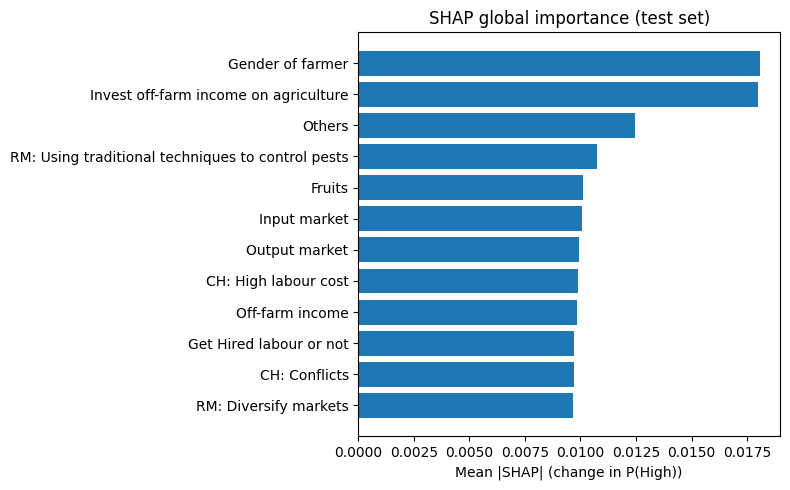

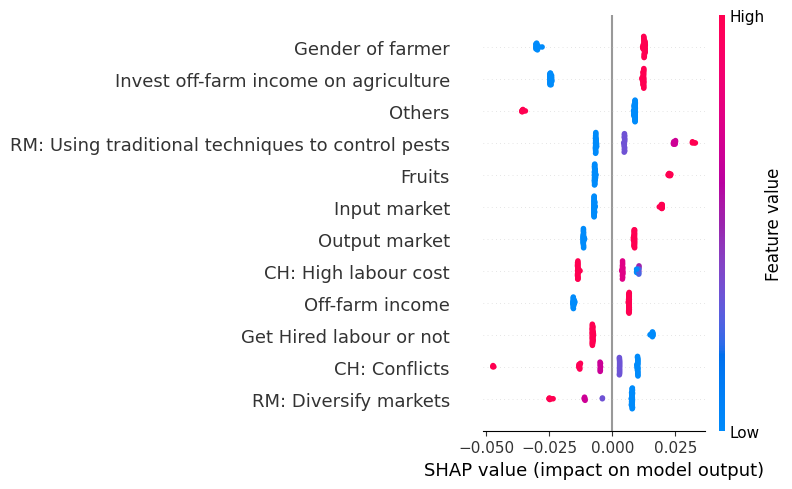

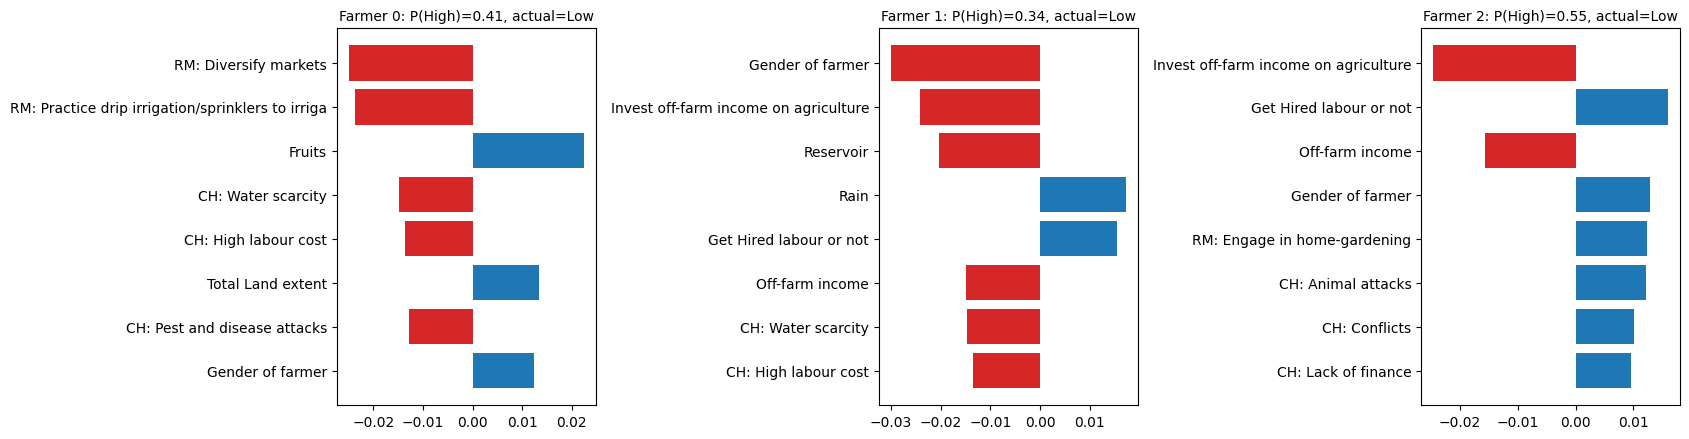

Gender of farmer                                     0.0181
Invest off-farm income on agriculture                0.0180
Others                                               0.0124
RM: Using traditional techniques to control pests    0.0108
Fruits                                               0.0101
Input market                                         0.0101
Output market                                        0.0099
CH: High labour cost                                 0.0099
Off-farm income                                      0.0098
Get Hired labour or not                              0.0097
dtype: float64

In [ ]:
# SHAP on the trained EBM (post-hoc, model-agnostic permutation explainer; categoricals label-encoded)
import shap
from sklearn.metrics import accuracy_score, roc_auc_score
cols = X.columns.tolist()
cats = {c: sorted(X[c].unique()) for c in cat_cols}
enc = lambda D: D.assign(**{c: D[c].map({v: i for i, v in enumerate(cats[c])}) for c in cat_cols}).astype(float)
def dec(a):
    D = pd.DataFrame(a, columns=cols)
    for c in cat_cols:
        D[c] = D[c].round().astype(int).map(dict(enumerate(cats[c])))
    return D
f = lambda a: ebm.predict_proba(dec(a))[:, 1]
bg = enc(X_tr.sample(30, random_state=SEED)).values
expl = shap.Explainer(f, bg, algorithm='permutation', seed=SEED)
sv = expl(enc(X_te).values, max_evals=300)
S = pd.DataFrame(sv.values, columns=cols)
shap_imp = S.abs().mean().sort_values(ascending=False)
shap_imp.to_csv('out/shap_importance.csv'); S.to_csv('out/shap_values.csv', index=False)
print('mean predicted P(High) (SHAP base value):', round(float(np.mean(sv.base_values)), 3))

t = shap_imp.head(12)[::-1]
plt.figure(figsize=(8, 5)); plt.barh(t.index, t.values)
plt.xlabel('Mean |SHAP| (change in P(High))'); plt.title('SHAP global importance (test set)')
plt.tight_layout(); plt.savefig('out/fig_shap_bar.png', dpi=200); plt.show()

shap.summary_plot(sv.values, enc(X_te), max_display=12, show=False)
plt.gcf().set_size_inches(8, 5); plt.tight_layout(); plt.savefig('out/fig_shap_summary.png', dpi=200); plt.show()

fig, axs = plt.subplots(1, 3, figsize=(17, 4.5))
for i, a in enumerate(axs):
    s = S.iloc[i].sort_values(key=abs).tail(8)
    a.barh(s.index, s.values, color=['tab:red' if v < 0 else 'tab:blue' for v in s.values])
    a.set_title(f"Farmer {i}: P(High)={ebm.predict_proba(X_te.iloc[[i]])[0, 1]:.2f}, actual={'High' if y_te.iloc[i] else 'Low'}", fontsize=10)
plt.tight_layout(); plt.savefig('out/fig_shap_local.png', dpi=200); plt.show()
display(shap_imp.head(10).round(4))

In [ ]:
# agreement between the three importance measures (EBM built-in, SHAP, permutation)
cmp = pd.DataFrame({'EBM': pd.Series(ebm.term_importances(), index=ebm.term_names_),
                    'SHAP': shap_imp, 'Permutation': pi_s}).dropna()
rho = cmp.corr(method='spearman').round(2)
rho.to_csv('out/importance_agreement.csv'); display(rho)
top8 = pd.DataFrame({m: cmp[m].sort_values(ascending=False).head(8).index.tolist() for m in cmp})
top8.index = range(1, 9); top8.to_csv('out/top8_by_method.csv'); display(top8)

,EBM,SHAP,Permutation
EBM,1.00,0.97,-0.08
SHAP,0.97,1.00,-0.09
Permutation,-0.08,-0.09,1.00


,EBM,SHAP,Permutation
1,Gender of farmer,Gender of farmer,RM: Practice drip irrigation/sprinklers to irriga
2,Invest off-farm income on agriculture,Invest off-farm income on agriculture,Agro-well
3,Others,Others,RM: Using traditional techniques to control pests
4,Off-farm income,RM: Using traditional techniques to control pests,Output market
5,CH: Water scarcity,Fruits,Household size
6,Input market,Input market,CH: Lack of micro credits
7,RM: Practice drip irrigation/sprinklers to irriga,Output market,CH: Lack of labor
8,Get Hired labour or not,CH: High labour cost,Gender of household head


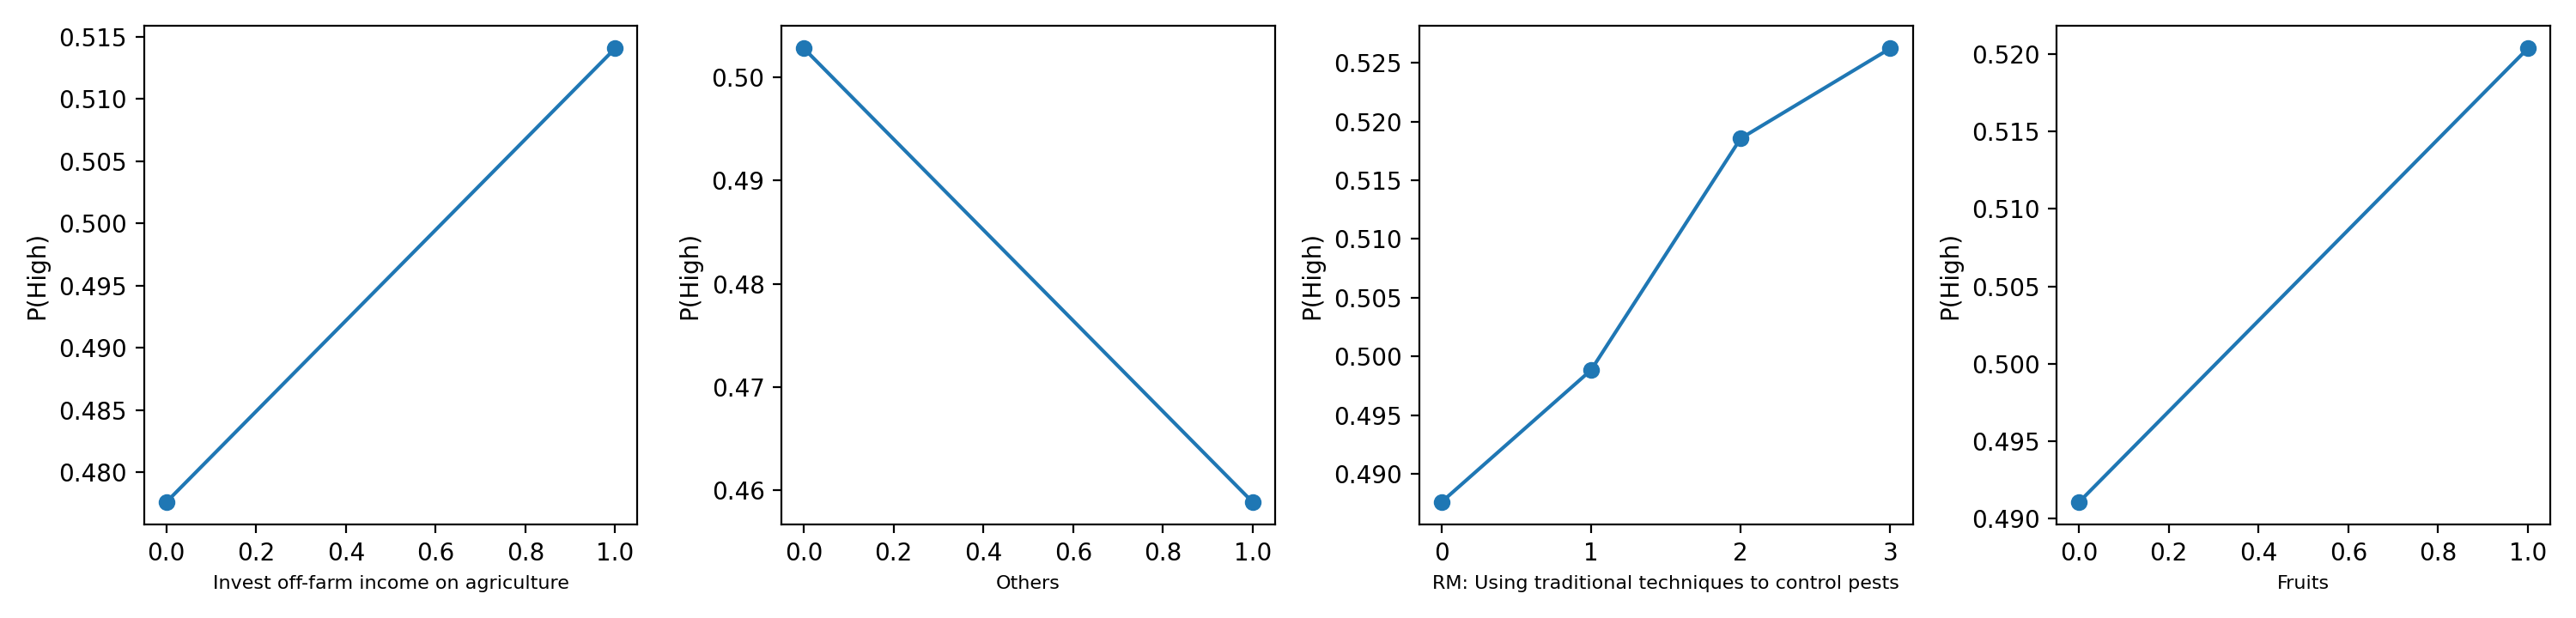

In [ ]:
# partial dependence of the most important numeric/binary features (probability scale), computed directly
top = [c for c in shap_imp.index if c in num_cols][:4]
fig, ax = plt.subplots(1, 4, figsize=(15, 3.6))
for a, c in zip(ax, top):
    vals = np.unique(X_tr[c]) if X_tr[c].nunique() <= 10 else np.unique(np.quantile(X_tr[c], np.linspace(0, 1, 21)))
    pdp = []
    for v in vals:
        D = X_tr.copy(); D[c] = v
        pdp.append(ebm.predict_proba(D)[:, 1].mean())
    a.plot(vals, pdp, marker='o'); a.set_xlabel(c, fontsize=8); a.set_ylabel('P(High)')
plt.tight_layout(); plt.savefig('out/fig_pdp.png', dpi=200); plt.show()


In [ ]:
# result tables: per-class metrics and bootstrap 95% CI on the test set
from sklearn.metrics import precision_recall_fscore_support
pr, rc, f1, sup = precision_recall_fscore_support(y_te, ebm.predict(X_te))
cls_tbl = pd.DataFrame({'Precision': pr, 'Recall': rc, 'F1': f1, 'Support': sup}, index=['Low', 'High']).round(3)
cls_tbl.to_csv('out/ebm_class_report.csv'); display(cls_tbl)

yt, rng, rows = y_te.values, np.random.default_rng(SEED), {}
for n, m in models.items():
    p = m.predict_proba(X_te)[:, 1]; a_, u_ = [], []
    for _ in range(1000):
        i = rng.integers(0, len(yt), len(yt))
        if len(set(yt[i])) < 2: continue
        a_.append(accuracy_score(yt[i], p[i] >= .5)); u_.append(roc_auc_score(yt[i], p[i]))
    rows[n] = {'Accuracy 95% CI': f'{np.percentile(a_, 2.5):.2f} to {np.percentile(a_, 97.5):.2f}',
               'AUC 95% CI': f'{np.percentile(u_, 2.5):.2f} to {np.percentile(u_, 97.5):.2f}'}
ci = pd.DataFrame(rows).T; ci.to_csv('out/bootstrap_ci.csv'); display(ci)

,Precision,Recall,F1,Support
Low,0.605,0.767,0.676,30
High,0.682,0.500,0.577,30


,Accuracy 95% CI,AUC 95% CI
Logistic Regression,0.47 to 0.72,0.44 to 0.73
Random Forest,0.55 to 0.78,0.62 to 0.87
Gradient Boosting,0.55 to 0.78,0.52 to 0.79
EBM,0.52 to 0.75,0.52 to 0.78


,Gender,n,Actual High %,Predicted High %,Accuracy
0,Female,19,47.4,26.3,0.684
1,Male,41,51.2,41.5,0.610


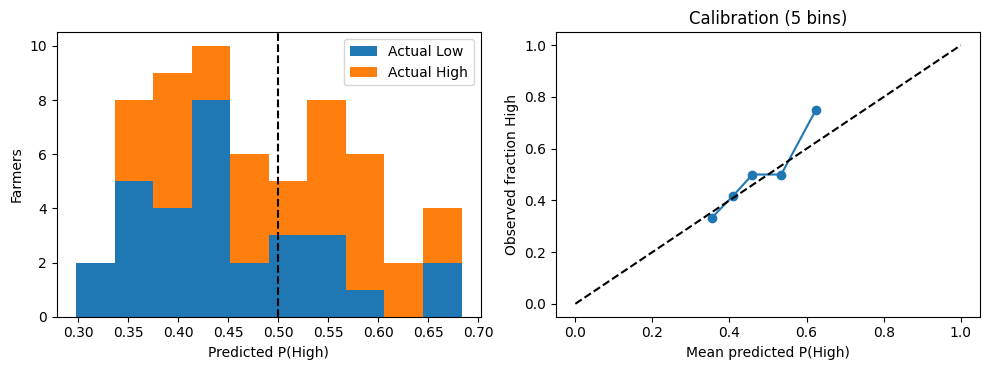

In [ ]:
# subgroup (gender) performance, probability distribution and calibration
from sklearn.calibration import calibration_curve
p = ebm.predict_proba(X_te)[:, 1]; g = X_te['Gender of farmer'].values; yv = y_te.values
sub = pd.DataFrame([{'Gender': v, 'n': int((g == v).sum()), 'Actual High %': round(100 * yv[g == v].mean(), 1),
                     'Predicted High %': round(100 * (p[g == v] >= .5).mean(), 1),
                     'Accuracy': round(accuracy_score(yv[g == v], p[g == v] >= .5), 3)} for v in np.unique(g)])
sub.to_csv('out/subgroup_gender.csv', index=False); display(sub)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
ax[0].hist([p[yv == 0], p[yv == 1]], bins=10, stacked=True, label=['Actual Low', 'Actual High'])
ax[0].axvline(.5, color='k', ls='--'); ax[0].set(xlabel='Predicted P(High)', ylabel='Farmers'); ax[0].legend()
fo, mp = calibration_curve(y_te, p, n_bins=5, strategy='quantile')
ax[1].plot(mp, fo, 'o-'); ax[1].plot([0, 1], [0, 1], 'k--')
ax[1].set(xlabel='Mean predicted P(High)', ylabel='Observed fraction High', title='Calibration (5 bins)')
plt.tight_layout(); plt.savefig('out/fig_prob_calibration.png', dpi=200); plt.show()

In [13]:
# save model
joblib.dump(ebm, 'out/ebm.joblib')
meta = {'columns': X.columns.tolist(),
        'numeric': {c: [float(X[c].min()), float(X[c].max()), float(X[c].median())] for c in num_cols},
        'categorical': {c: sorted(X[c].unique().tolist()) for c in cat_cols}}
json.dump(meta, open('out/meta.json', 'w'), indent=1)
X.assign(high_resilience=y).to_csv('out/clean_data.csv', index=False)
shutil.make_archive('results', 'zip', 'out')
files.download('results.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>